# Extended Data Fig. 11: rats: SWRs, replay and BARRs (panels)

Reads its tables from `../csv/FigS11_AF_rats/`; panels are saved to `../figure_output/supplementary/FigS11/`. c, d and f are drawn by the first-submission rat notebook (Previous_Rv1 `FigS5_S6_rats`) on non-overlapping windows; b, e and the schematic in a are from Extended Data Fig. 6 of the first submission (`assets/Extended Data Fig6.svg`). d2 = d2 (2024 Euclidean, AR p = 20); rat sessions keep their bin sizes (40–80 ms) and window lengths (30 / 60 s). Stars: *p < 0.05, **p < 0.01, ***p < 0.001, ****p < 0.0001.

- **a** d2 presleep vs postsleep, NREM session means, 17 sessions / 2 rats; session-paired signed-rank.
- **b** Branching ratio around SWR starts (example) and per-session ΔBR inset; inset: session-paired signed-rank, SWRs vs shuffle.
- **c** d2 (z) by replay / non-replay SWR-rate sextile, 15 sessions; slopes over the 6 sextile means.
- **d** ISI entropy (z) by SWR-rate sextile, 25 sessions; per-session Spearman, signed-rank.
- **e** Branching ratio around BARR starts and per-session ΔBR inset (as b).
- **f** d2 (z) and ISI entropy (z) by BARR-rate sextile, 12 sessions; linear trend over the 6 sextile means; per-session tests in `stats.csv`.

In [1]:
import os, sys, re, json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sys.path.insert(0, os.path.abspath('.'))           # figure_scripts
import final_figs as F                             # styles, save, stars, crops

CSV = os.path.join(F.REPO, "csv", "FigS11_AF_rats")
read = lambda name, **k: pd.read_csv(os.path.join(CSV, name), float_precision="round_trip", **k)   # noqa: E731
STC = read("stats.csv").set_index(["panel", "quantity"]).value     # every number printed on a panel
RC = json.load(open(os.path.join(CSV, "rcparams.json"), encoding="utf-8"))


def rc(fig_id, when):
    """matplotlib's settings when this panel was created ("draw") or saved ("save")"""
    mpl.rcdefaults()
    mpl.rcParams.update(RC[fig_id][when])

## Data and statistics

In [2]:
# Extended Data Fig. 11 = the submitted Extended Data Fig. 6 (rats) on non-overlapping windows:
#   a  d2 presleep vs postsleep        (lab: Previous_Rv1 FigS5_S6_rats summary_df, session means), d2 only
#   b  BR around SWRs + dBR            cut from Extended Data Fig6.svg (event-level), the inset star per session
#   c  d2 by replay / non-replay SWR-rate sextile   (lab: FigS5_S6_rats on the rebuilt disjoint tiles)
#   d  ISI entropy by SWR-rate sextile (lab: FigS5_S6_rats on the thinned, re-tiled windows)
#   e  BR around BARRs + dBR           submitted, cut (as b)
#   f  d2 and ISI entropy by BARR-rate sextile   (lab: FigS5_S6_rats on the rebuilt disjoint tables)
# Statistics: a session-paired signed-rank; b, e insets session-paired signed-rank of the per-session mean dBR (event
# vs shuffle); d per session -- Spearman rho(entropy, SWR rate) over each session's windows, signed-rank of the rhos;
# c and f: the notebook's linear trend over the 6 sextile means (n = 6).
ST = {}
PA = read("a_prepost_sessions.csv", index_col="animal_day")        # d2 per session, presleep / postsleep
dA = PA.Postsleep - PA.Presleep
ST["a"] = dict(n=len(PA), up=int((dA > 0).sum()), direction="↑", mean_diff=float(dA.mean()),
               p=float(stats.wilcoxon(PA.Postsleep, PA.Presleep).pvalue))
INSET = read("be_inset_sessions.csv")                                # per session mean dBR, event / shuffle
for k, g in INSET.groupby("panel"):
    up = np.median(g["diff"]) > 0
    ST[k] = dict(n=len(g), up=int((g["diff"] > 0).sum()) if up else int((g["diff"] < 0).sum()), direction="↑" if up else "↓",
                 p=float(stats.wilcoxon(g.dBR_event, g.dBR_shuffle).pvalue))
rho = read("d_session_rho.csv").rho                                  # per session Spearman rho, d
up = np.median(rho) > 0
ST["d"] = dict(n=len(rho), up=int((rho > 0).sum()) if up else int((rho < 0).sum()), direction="↑" if up else "↓",
               rho_median=float(np.median(rho)), p=float(stats.wilcoxon(rho).pvalue))
ST["c"] = dict(slope_in=STC["c", "slope_replay"], slope_out=STC["c", "slope_nonreplay"],
               diff=STC["c", "slope_difference"], p_diff=STC["c", "p_difference"])
for k in ("d2", "isi"):
    ST[f"f_{k}"] = dict(r=STC["f", f"r_{k}"], p=STC["f", f"p_{k}"])
print(f"a: post vs pre, two-sided paired Wilcoxon signed-rank p = {ST['a']['p']:.2g}; n = {ST['a']['n']} sessions")
for k, what in (("b", "SWRs vs shuffle"), ("e", "BARRs vs shuffle")):
    print(f"{k} inset: {what}, two-sided paired Wilcoxon signed-rank p = {ST[k]['p']:.2g}; n = {ST[k]['n']} sessions")
print(f"c: slope {ST['c']['slope_in']:.2f} (replay SWRs), {ST['c']['slope_out']:.2f} (non-replay SWRs); slope difference "
      f"{-ST['c']['diff']:.2f}, p = {ST['c']['p_diff']:.2g}")
print(f"d: per-session Spearman rho, two-sided Wilcoxon signed-rank p = {ST['d']['p']:.2g}; n = {ST['d']['n']} sessions")
for k in ("d2", "isi"):
    print(f"f {k}: six sextile means, Pearson r = {ST[f'f_{k}']['r']:.2f}, p = {ST[f'f_{k}']['p']:.2g}")

a: post vs pre, two-sided paired Wilcoxon signed-rank p = 0.035; n = 17 sessions
b inset: SWRs vs shuffle, two-sided paired Wilcoxon signed-rank p = 8.3e-07; n = 24 sessions
e inset: BARRs vs shuffle, two-sided paired Wilcoxon signed-rank p = 0.0068; n = 11 sessions
c: slope 0.52 (replay SWRs), 0.25 (non-replay SWRs); slope difference 0.27, p = 0.021
d: per-session Spearman rho, two-sided Wilcoxon signed-rank p = 3e-07; n = 25 sessions
f d2: six sextile means, Pearson r = -0.89, p = 0.018
f isi: six sextile means, Pearson r = 0.85, p = 0.032


## Panels

cropped Extended Data Fig6.svg [5.5, 4.3, 31.5 x 12.6] -> figure_output\supplementary\FigS11\FigS11_A_schematic_prepost.svg (31.5 x 12.6 mm)


cropped Extended Data Fig6.svg [39.6, 0.6, 46.0 x 55.8] -> figure_output\supplementary\FigS11\FigS11_B_br_around_swr.svg (46.0 x 55.8 mm)


cropped Extended Data Fig6.svg [8.6, 59.6, 61.0 x 45.6] -> figure_output\supplementary\FigS11\FigS11_E_br_around_barr.svg (61.0 x 45.6 mm)


saved figure_output\supplementary\FigS11\FigS11_A_prepost_d2.svg / .png


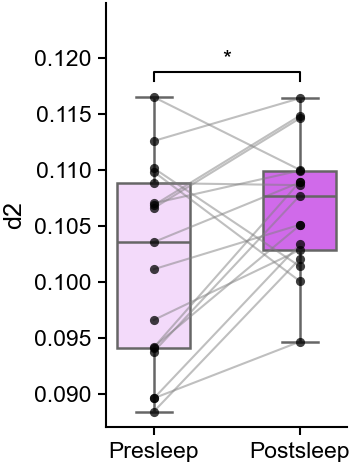

saved figure_output\supplementary\FigS11\FigS11_C_d2_by_replay_swr_rate.svg / .png


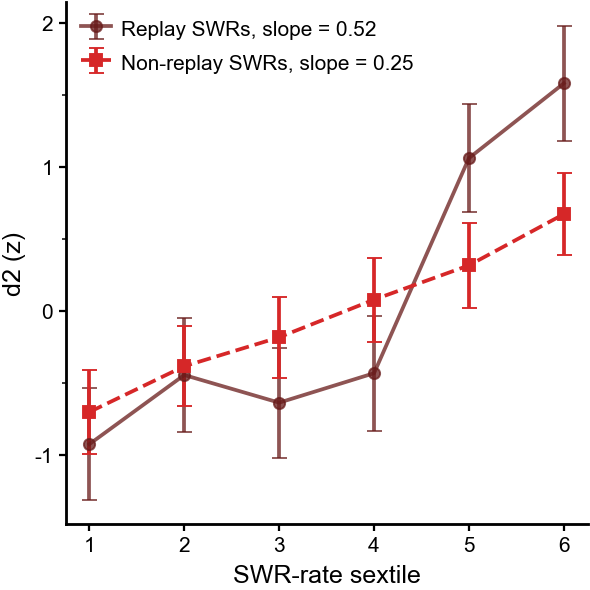

saved figure_output\supplementary\FigS11\FigS11_D_isi_entropy_by_swr_rate.svg / .png


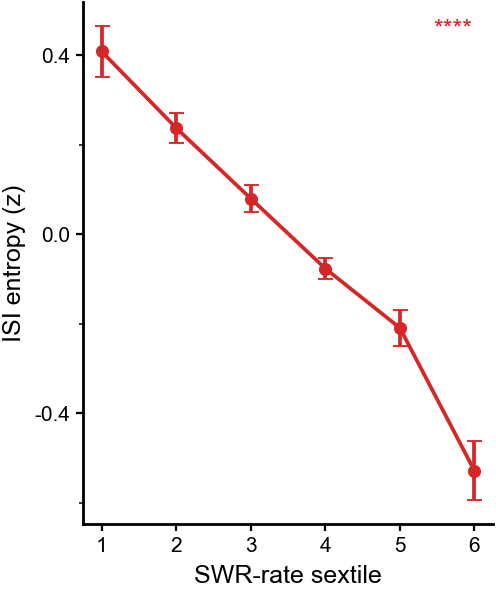

saved figure_output\supplementary\FigS11\FigS11_F_d2_by_barr_rate.svg / .png


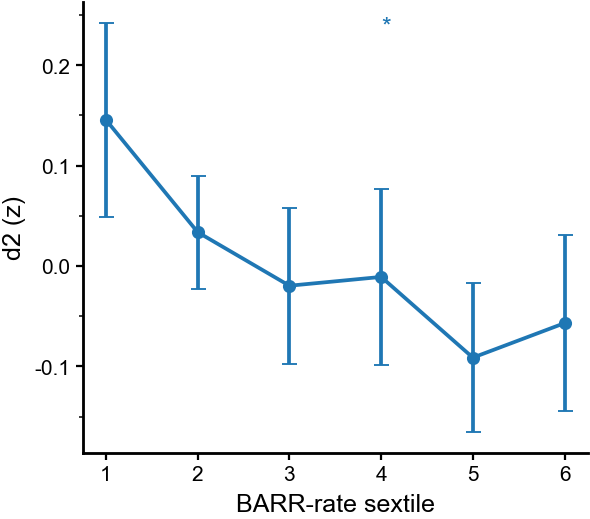

saved figure_output\supplementary\FigS11\FigS11_F_isi_entropy_by_barr_rate.svg / .png


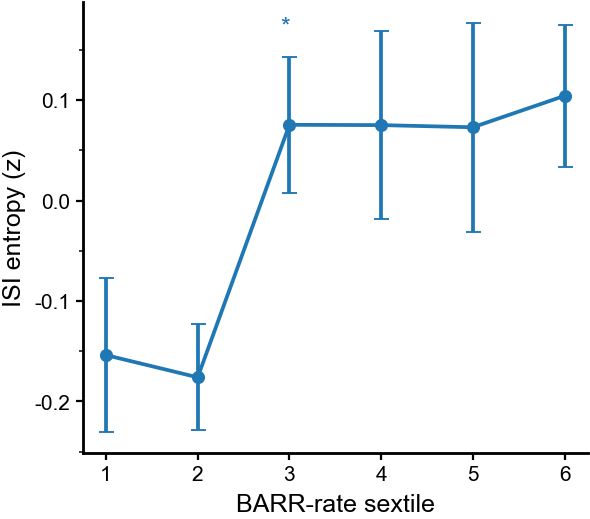

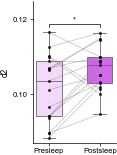

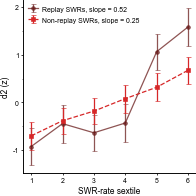

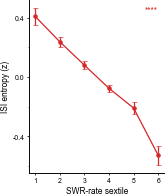

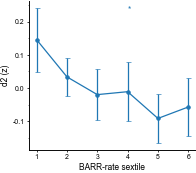

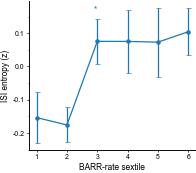

In [3]:
ED6 = os.path.join(CSV, "assets", "Extended Data Fig6.svg")      # the submitted figure, mm units

# ---- a (top), b, e: cropped from the submitted figure (b, e: event-level BR around SWRs / BARRs, the example
# animal and the per-session dBR inset)
F.crop_svg(ED6, "FigS11_A_schematic_prepost", 5.5, 4.3, 31.5, 12.6, unit_mm=1.0)
F.crop_svg(ED6, "FigS11_B_br_around_swr", 39.6, 0.6, 46.0, 55.8, drop_ids=["text910277-5"], unit_mm=1.0)   # 1.2 mm headroom above the inset bracket
F.crop_svg(ED6, "FigS11_E_br_around_barr", 8.6, 59.6, 61.0, 45.6, drop_ids=["text910277-5-16-1-1-1"], unit_mm=1.0)


def edit_crop(fig_id, formal):
    """Replace tspan texts {id: text or (text, y)} in a cut panel; a y moves the tspan's baseline (its own units)."""
    import subprocess
    src = open(F.stem(fig_id) + ".svg", encoding="utf-8").read()
    for variant, edits in ((None, formal),):
        s = src
        for i, txt in edits.items():
            txt, y = txt if isinstance(txt, tuple) else (txt, None)
            m = re.search(r'(<tspan\b[^>]*\bid="%s"[^>]*>)[^<]*(</tspan>)' % re.escape(i), s)
            assert m, (fig_id, i)
            tag = m.group(1) if y is None else re.sub(r'\by="[^"]*"', f'y="{y}"', m.group(1))
            s = s[:m.start()] + tag + txt + m.group(2) + s[m.end():]
            if y is not None:                          # a sodipodi:role="line" tspan is placed from its <text>'s y
                t0 = s.rfind("<text", 0, m.start())
                t1 = s.index(">", t0)
                s = s[:t0] + re.sub(r'\by="[^"]*"', f'y="{y}"', s[t0:t1]) + s[t1:]
        out = F.stem(fig_id) if variant is None else os.path.join(os.path.dirname(F.stem(fig_id)), variant, fig_id)
        os.makedirs(os.path.dirname(out), exist_ok=True)
        open(F.assert_local_path(out + ".svg"), "w", encoding="utf-8").write(s)
        subprocess.run([F.INKSCAPE, out + ".svg", "--export-type=png", "--export-dpi=600", "--export-background=#ffffff",
                        f"--export-filename={out}.png"], capture_output=True)


# the insets' stars -> the per-session test; e's bottom y tick is set to 0.85, evenly spaced with the other three
# (0.88 / 0.87 / 0.86)
sb, se = ST["b"], ST["e"]
edit_crop("FigS11_B_br_around_swr", {"tspan76756-5": F.stars(sb["p"])})
edit_crop("FigS11_E_br_around_barr", {"tspan76756-5-1": F.stars(se["p"]), "tspan83062-6-0": "0.85"})

# ---- a: d2 presleep vs postsleep, session means (NREM), as Extended Data Fig. 6a / Fig 2a
rc("FigS11_A_prepost_d2", "draw")                   # lab: F.final_style()
S = PA.rename_axis("session").reset_index().melt(id_vars="session", var_name="epoch2", value_name="d2")
order, pal = ["Presleep", "Postsleep"], {"Presleep": "#f6d5ff", "Postsleep": "#dd55ff"}
fig, ax = plt.subplots(figsize=(31.5 * F.MM, 41 * F.MM), layout="constrained")
sns.boxplot(data=S, x="epoch2", y="d2", order=order, hue="epoch2", hue_order=order, palette=pal, legend=False,
            showfliers=False, width=0.5, linewidth=0.6, ax=ax, zorder=2)
sns.stripplot(data=S, x="epoch2", y="d2", order=order, color="k", jitter=False, alpha=0.75, size=2.2, ax=ax, zorder=3)
for _, r in PA.iterrows():
    ax.plot([0, 1], [r.Presleep, r.Postsleep], color="gray", alpha=0.5, lw=0.5, zorder=2)
s = ST["a"]
top = S.d2.max()
span = top - S.d2.min()
F.bracket(ax, 0, 1, top + 0.08 * span, f"{s['up']}/{s['n']} ↑ {F.stars(s['p'])}", h=0.03 * span, fs=5.5)
ax.set_ylim(S.d2.min() - 0.05 * span, top + 0.3 * span)
ax.set_xlabel(""); ax.set_ylabel("d2")
rc("FigS11_A_prepost_d2", "save")
F.settle(fig)
F.drop_counts(fig)
F.show(F.save(fig, "FigS11_A_prepost_d2"))


# ---- c, d, f: in the lab, the rat notebook's own figures, run on disjoint windows and restyled to print size.
# Here each one's plotting code, from Previous_Rv1/sleep/figure_scripts/FigS5_S6_rats.ipynb, on the table it plots.
def finish(fig, fid, w, h, xl, yl, text=None, color="k", where=(0.5, 0.97), ha="center"):
    rc(fid, "save")                                # the lab restyles and saves under the settings the Rv1 run left
    ax = fig.axes[0]
    F.restyle(fig, w, h)
    ax.set_title("")
    if ax.get_legend() and fid != "FigS11_C_d2_by_replay_swr_rate":
        ax.get_legend().remove()                   # "mean ± SEM (across files)": the legend's text
    ax.set_xticks(range(1, 7)); ax.set_xticklabels([str(i) for i in range(1, 7)])
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    if text:
        ax.text(*where, text, transform=ax.transAxes, ha=ha, va="top", fontsize=6, color=color)
    F.sparse_yticks(ax)
    F.settle(fig)
    F.drop_counts(fig)
    F.show(F.save(fig, fid))


# c: replay (IN) vs non-replay (OUT) SWR rate -- mean over files and SE_total per sextile (summarize_across_files,
# exported); drawing: plot_mean_sem. The legend carries each arm's slope.
Cc = read("c_sextiles.csv")
mean_z = Cc.pivot(index="tile", columns="group", values="mean")
se_total = Cc.pivot(index="tile", columns="group", values="se_total")
colors = {"IN": "#691c1bc0", "OUT": "#d62728ff"}
rc("FigS11_C_d2_by_replay_swr_rate", "draw")
# ---- pasted: plot_mean_sem(mean_z, se_total, n_bins=6, title="Mean ± SE_total (...)", colors=colors)
xs = np.arange(1, 6 + 1)
fig, ax = plt.subplots(figsize=(4, 4))
for grp, fmt in [("IN", "o-"), ("OUT", "s--")]:
    y = mean_z.get(grp)
    e = se_total.get(grp)
    ax.errorbar(xs, y.values, yerr=e.values if e is not None else None,
                fmt=fmt, capsize=4, lw=2, label=grp, color=colors.get(grp) if colors else None)
ax.set_xticks(xs)
ax.set_xticklabels([f"Q{i}" for i in xs])
ax.set_xlabel("Rate sextiles (low → high)")
ax.set_ylabel("D² (z-scored within file)")
ax.set_title("Mean ± SE_total (between-file + within-file propagated)")
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
# ---- the lab cell
rc("FigS11_C_d2_by_replay_swr_rate", "save")
for h_ in ax.get_legend_handles_labels()[0]:
    lab = h_.get_label()
    h_.set_label(f"Replay SWRs, slope = {ST['c']['slope_in']:.2f}" if lab == "IN" else
                 f"Non-replay SWRs, slope = {ST['c']['slope_out']:.2f}" if lab == "OUT" else lab)
ax.set_xticks(range(1, 7))
ax.legend(frameon=False, loc="upper left", handlelength=1.6)
finish(fig, "FigS11_C_d2_by_replay_swr_rate", 50, 50, "SWR-rate sextile", "d2 (z)")

# d: ISI entropy by SWR-rate sextile -- mean and SEM over files of the per-file sextile means (exported);
# pasted: plot_isi_by_rate_tile_pooled_crossfileSEM
Dd = read("d_sextiles.csv")
rc("FigS11_D_isi_entropy_by_swr_rate", "draw")
xs, ys, es = Dd.tile.to_numpy(int), Dd["mean"].to_numpy(), Dd["sem"].to_numpy()
# ---- pasted
plt.figure(figsize=(5, 4))
plt.errorbar(xs, ys, yerr=es, fmt='-o', capsize=4, color="tab:red", linewidth=2, label="mean ± SEM (across files)")
plt.xticks(xs)
plt.xlabel("ISI entropy rate quantiles (low → high)")
plt.ylabel("ISI entropy (z)")
sns.despine()
ax = plt.gca()
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
# ---- the lab cell
s = ST["d"]
finish(plt.gcf(), "FigS11_D_isi_entropy_by_swr_rate", 42, 50, "SWR-rate sextile", "ISI entropy (z)",
       f"{s['up']}/{s['n']} {s['direction']} {F.stars(s['p'])}", color="tab:red", where=(0.95, 0.97), ha="right")

# f: d2 (z) and ISI entropy (z) by BARR-rate sextile -- mean over all windows and SEM over files of the per-file means
# (exported); pasted: plot_d2_by_rate_tile_mean_allwindows_sem_acrossfiles and its ISI twin
Ff = read("f_sextiles.csv")
for k, fid, xlab, ylab_rv1, yl, where in (
        ("d2", "FigS11_F_d2_by_barr_rate", "barrage rate quantiles (low → high)", "d2 distance (z)", "d2 (z)", (0.6, 0.97)),
        ("isi", "FigS11_F_isi_entropy_by_barr_rate", "Barrage rate quantiles (low → high)", "ISI entropy (z)",
         "ISI entropy (z)", (0.4, 0.97))):
    q = Ff[Ff.measure == k]
    xs, ys, es = q.tile.to_numpy(int), q.mean_all_windows.to_numpy(), q.sem_across_files.to_numpy()
    rc(fid, "draw")
    # ---- pasted
    plt.figure(figsize=(5, 4))
    plt.errorbar(xs, ys, yerr=es, fmt='-o', capsize=4, color="tab:blue",
                 linewidth=2, label="mean (all windows) ± SEM (across files)")
    plt.xticks(xs)
    plt.xlabel(xlab)
    plt.ylabel(ylab_rv1)
    sns.despine()
    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.legend(frameon=False, fontsize=9)
    plt.tight_layout()
    # ---- the lab cell
    finish(plt.gcf(), fid, 50, 44, "BARR-rate sextile", yl, F.stars(ST[f"f_{k}"]["p"]), color="tab:blue", where=where)